# Import Library

In [36]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Load Dataset

In [3]:
df = pd.read_csv("drug200.csv")

# EDA

In [46]:
# Data Exploration

print(f"10 data teratas\n {df.head(10)}")
print("\nInformasi dataset")
df.info()
print(f"\nRingkasan statistik\n {df.describe()}\n")
print(f"Dataset ini berisi {df.shape[0]} baris dan {df.shape[1]} kolom\n")
print(f"Nama nama kolom : {df.columns}")

10 data teratas
    Age Sex      BP Cholesterol  Na_to_K   Drug
0   23   F    HIGH        HIGH   25.355  drugY
1   47   M     LOW        HIGH   13.093  drugC
2   47   M     LOW        HIGH   10.114  drugC
3   28   F  NORMAL        HIGH    7.798  drugX
4   61   F     LOW        HIGH   18.043  drugY
5   22   F  NORMAL        HIGH    8.607  drugX
6   49   F  NORMAL        HIGH   16.275  drugY
7   41   M     LOW        HIGH   11.037  drugC
8   60   M  NORMAL        HIGH   15.171  drugY
9   43   M     LOW      NORMAL   19.368  drugY

Informasi dataset
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          200 non-null    int64  
 1   Sex          200 non-null    str    
 2   BP           200 non-null    str    
 3   Cholesterol  200 non-null    str    
 4   Na_to_K      200 non-null    float64
 5   Drug         200 non-null    str    
dtypes: float64(1)

In [53]:
# Handle missing values
print("Cek missing values")
df.isnull().sum()

Cek missing values


Age            0
Sex            0
BP             0
Cholesterol    0
Na_to_K        0
Drug           0
dtype: int64

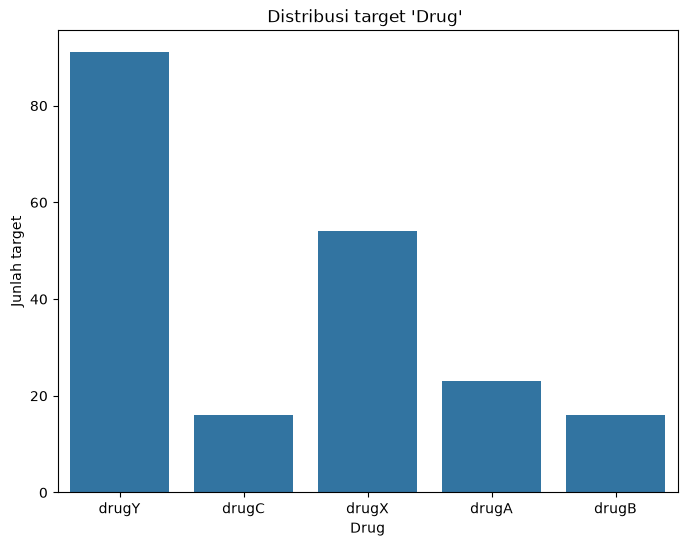

In [ ]:
# Visualisasi distribusi target
plt.figure(figsize=(8,6))
sns.countplot(x="Drug", data=df)
plt.title("Distribusi target 'Drug' ")
plt.ylabel("Junlah target")
plt.show()

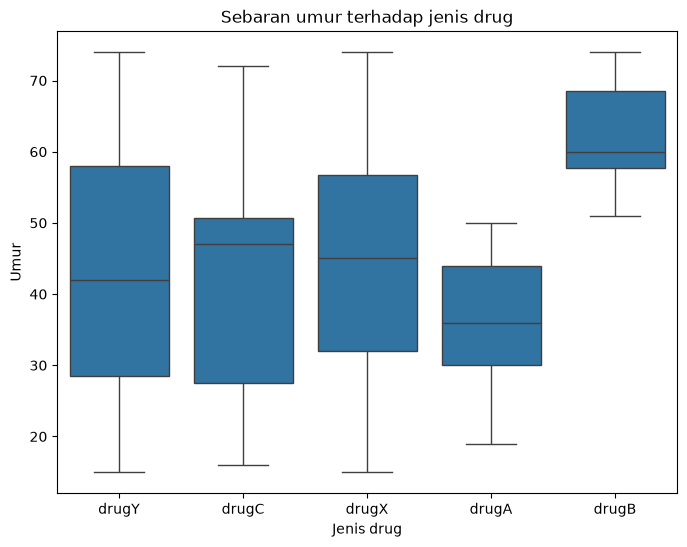

In [ ]:
# Visualisasi sebaran fitur 
plt.figure(figsize=(8,6))
sns.boxplot(x="Drug", y="Age", data=df)
plt.title("Sebaran umur terhadap jenis drug")
plt.xlabel("Jenis drug")
plt.ylabel("Umur")
plt.show()

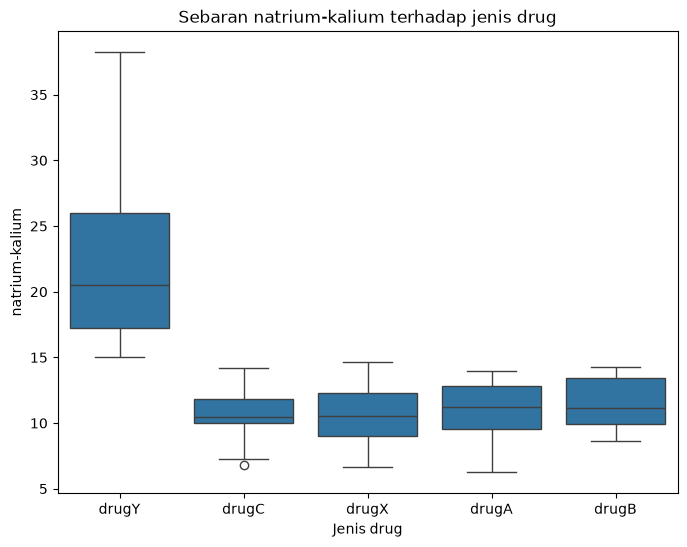

Ada outlier di drugC


In [ ]:
# Visualisasi sebaran fitur 
plt.figure(figsize=(8,6))
sns.boxplot(x="Drug", y="Na_to_K", data=df)
plt.title("Sebaran natrium-kalium terhadap jenis drug")
plt.xlabel("Jenis drug")
plt.ylabel("natrium-kalium")
plt.show()

print("Ada outlier di drugC")

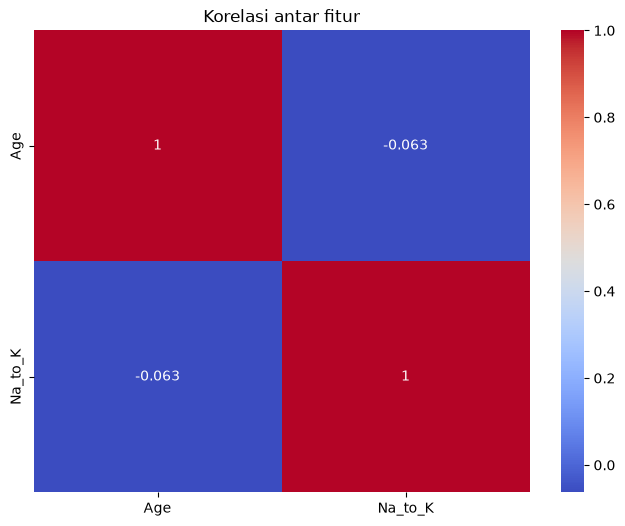

In [49]:
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(numeric_only=True), cmap="coolwarm", cbar=True, annot=True)
plt.title("Korelasi antar fitur")
plt.show()

# Preprocessing 

In [23]:
# feature selection
X = df.drop(columns=['Drug'])
y = df['Drug']

# encoding sederhana
X = pd.get_dummies(X, drop_first=True)
print(X.head())

   Age  Na_to_K  Sex_M  BP_LOW  BP_NORMAL  Cholesterol_NORMAL
0   23   25.355  False   False      False               False
1   47   13.093   True    True      False               False
2   47   10.114   True    True      False               False
3   28    7.798  False   False       True               False
4   61   18.043  False    True      False               False


# Split Data

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=67
)

print(f"Jumlah data latih : {len(X_train)}")
print(f"Jumlah data uji : {len(y_train)}")

Jumlah data latih : 160
Jumlah data uji : 160


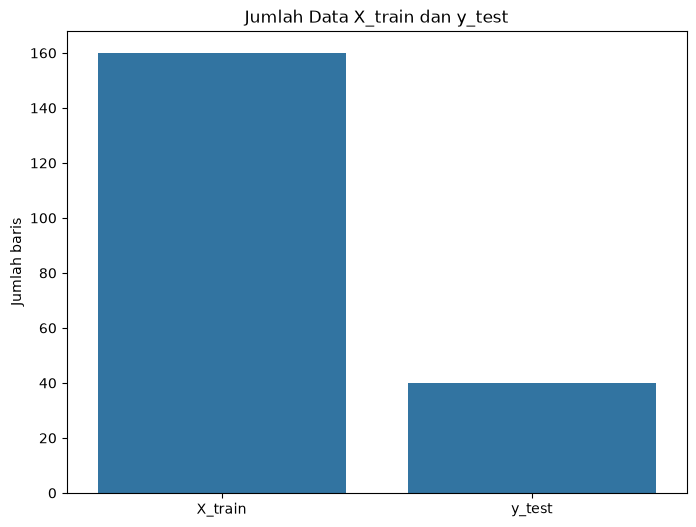

In [44]:
labels = ["X_train", "y_test"]
counts = [len(X_train), len(y_test)]

plt.figure(figsize=(8, 6))
sns.barplot(x=labels, y=counts)
plt.title("Jumlah Data X_train dan y_test")
plt.ylabel("Jumlah baris")
plt.show()

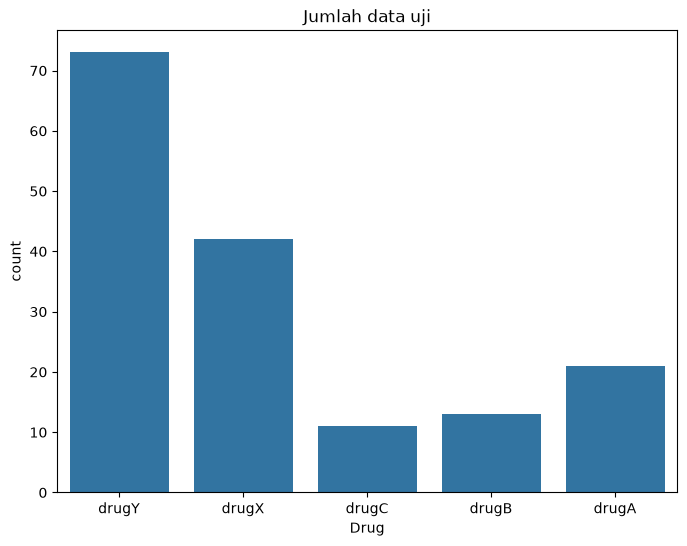

In [29]:
plt.figure(figsize=(8,6))
sns.countplot(x=y_train)
plt.title("Jumlah data uji")
plt.show()

# Modeling

In [ ]:
# membangun model
clf = DecisionTreeClassifier(max_depth=5, random_state=67)

# fit 
clf.fit(X_train, y_train)

# memprediksi
y_pred = clf.predict(X_test)

# Evaluasi Model

In [40]:
# menghitung akurasi menggunakan beberapa matriks
akurasi = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)
print("=== Akurasi Model Decision Tree ===")
print(f"Akurasi : {akurasi*100:.2f}%\n")
print(f"Classification Report : \n{report}")

=== Akurasi Model Decision Tree ===
Akurasi : 100.00%

Classification Report : 
              precision    recall  f1-score   support

       drugA       1.00      1.00      1.00         2
       drugB       1.00      1.00      1.00         3
       drugC       1.00      1.00      1.00         5
       drugX       1.00      1.00      1.00        12
       drugY       1.00      1.00      1.00        18

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40



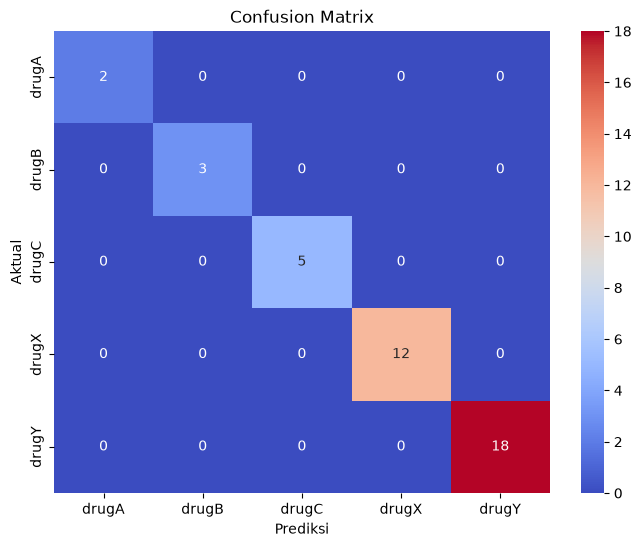

In [50]:
# membuat confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8,6))
sns.heatmap(cm, cmap='coolwarm', cbar=True, annot=True, fmt='d', xticklabels=clf.classes_, yticklabels=clf.classes_)
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.title("Confusion Matrix")
plt.show()

# Visualisasi Decision Tree

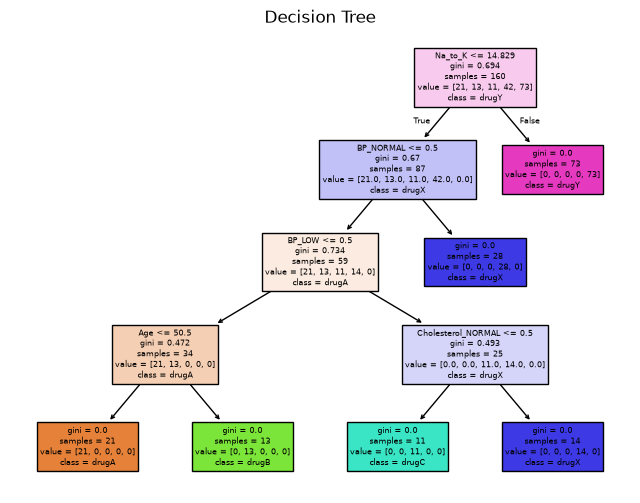

In [51]:
plt.figure(figsize=(8,6))
plot_tree(clf, feature_names=X.columns, class_names=['drugA', 'drugB', 'drugC', 'drugX', 'drugY'], filled=True)
plt.title("Decision Tree")
plt.show()